# Flight delay exploratory data analysis

**January 2026 | 10 project origin airports | Departure delay of at least 15 minutes**

This notebook investigates the flight data before reusable feature engineering and model training.
The scope is **ATL, DEN, DFW, JFK, LAX, MSP, ORD, PHX, SEA, and SFO**. Destinations are unrestricted.
The database retains nationwide data; analysis here uses only departures from these ten origins.

The target is `departure_delayed_15`. The modelling population is **noncancelled flights with a recorded target**.
Cancellation rates are reported separately before this exclusion. Diversion alone is not an exclusion for a departure-delay task.

### Questions
1. Is the scoped data complete, consistent, and usable?
2. How common are delays, and how do they vary by schedule, airline, and origin?
3. What do distance and scheduled duration tell us about the data?
4. Which features should we implement, and which fields would leak future information?

**Reproducibility:** run all cells from top to bottom with the project database running and its password in the untracked `.env` file.
Required packages: pandas, numpy, matplotlib, seaborn, SQLAlchemy, psycopg2-binary, python-dotenv, and an IPython notebook kernel.
The notebook makes read-only database queries and saves PNG figures under `reports/figures/`.
It performs no inserts, updates, schema changes, or model fitting. No live map or external airport download is needed.

**Verified cohort:** 161,992 eligible flights, 36,283 delayed (22.40%). All figures and findings below use the ten-origin scope unless explicitly labelled as a source audit or cancellation analysis.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
from sqlalchemy import create_engine, URL, text, bindparam
from dotenv import load_dotenv
from IPython.display import display, Markdown

# Work from the repository root or either capitalization of the notebooks directory.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "compose.yaml").exists() and (p / "src").is_dir()),
    None
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside aviation_mlops_platform.")

load_dotenv(project_root / ".env")
PROJECT_AIRPORTS = ["ATL", "DEN", "DFW", "JFK", "LAX", "MSP", "ORD", "PHX", "SEA", "SFO"]
START_DATE, END_DATE = "2026-01-01", "2026-02-01"  # End is exclusive.
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE = "#3978A8", "#D47838"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SCOPE_LABEL = "January 2026 | 10 project origins | Noncancelled, labelled flights"
exported_figures = []

def finish_figure(fig, filename):
    fig.tight_layout()
    path = figures_dir / filename
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    exported_figures.append(filename)
    plt.show()
    plt.close(fig)

def delay_summary(frame, group):
    result = frame.groupby(group, observed=True).agg(
        flights=("flight_id", "size"),
        delayed_flights=("departure_delayed_15", "sum"),
        delay_rate=("departure_delayed_15", "mean")
    )
    # Ordinary floats preserve empty-group NaN values for Matplotlib.
    result["delay_rate"] = result["delay_rate"].astype("float64")
    result["delayed_percent"] = result["delay_rate"] * 100
    return result

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | SQLAlchemy {sqlalchemy.__version__}")

Python 3.10.18 | pandas 2.1.4 | matplotlib 3.7.5 | seaborn 0.13.2 | SQLAlchemy 2.0.57


## 1. Load the source data and establish scope

The nationwide audit gives provenance only; it is **not** the denominator for later charts.
A left join preserves any flight missing an outcome so that a failed relationship cannot disappear silently.
The scoped query retrieves original stored values, including source anomalies, rather than the cleaned SQL feature view.
Both queries run in one read-only, repeatable-read transaction for a consistent snapshot.

In [2]:
database_url = URL.create(
    "postgresql+psycopg2", username="aviation", password=os.environ["POSTGRES_PASSWORD"],
    host="localhost", port=5433, database="aviation_mlops"
)
engine = create_engine(
    database_url,
    connect_args={"options": "-c default_transaction_read_only=on", "connect_timeout": 10}
)
query = text("""
    SELECT f.flight_id, f.flight_date, f.day_of_week, f.carrier,
           f.origin, f.destination, f.scheduled_departure_hhmm,
           f.scheduled_arrival_hhmm, f.scheduled_elapsed_minutes, f.distance_miles,
           o.flight_id AS outcome_flight_id, o.departure_delay_minutes,
           o.departure_delayed_15, o.cancelled, o.diverted
    FROM flights AS f
    LEFT JOIN flight_outcomes AS o ON f.flight_id = o.flight_id
    WHERE f.origin IN :airports
      AND f.flight_date >= :start_date AND f.flight_date < :end_date
    ORDER BY f.flight_id
""").bindparams(bindparam("airports", expanding=True))
try:
    with engine.connect().execution_options(isolation_level="REPEATABLE READ") as connection:
        with connection.begin():
            source_audit = pd.read_sql_query(text("""
                SELECT COUNT(*) AS stored_flights,
                       COUNT(o.flight_id) AS matched_outcomes,
                       COUNT(*) FILTER (WHERE o.flight_id IS NULL) AS missing_outcomes,
                       MIN(f.flight_date) AS first_date, MAX(f.flight_date) AS last_date
                FROM flights f LEFT JOIN flight_outcomes o USING (flight_id)
            """), connection)
            df = pd.read_sql_query(
                query, connection,
                params={"airports": PROJECT_AIRPORTS, "start_date": START_DATE, "end_date": END_DATE},
                parse_dates=["flight_date"]
            )
finally:
    engine.dispose()

for column in ["departure_delayed_15", "cancelled", "diverted"]:
    df[column] = df[column].astype("boolean")
for column in ["scheduled_elapsed_minutes", "distance_miles", "departure_delay_minutes"]:
    df[column] = pd.to_numeric(df[column], errors="raise")

print("Nationwide source audit (context only):")
display(source_audit)
print(f"Scoped scheduled flights, including cancellations: {len(df):,}")
display(df.head())

Nationwide source audit (context only):


,stored_flights,matched_outcomes,missing_outcomes,first_date,last_date
0,544003,544003,0,2026-01-01,2026-01-31


Scoped scheduled flights, including cancellations: 168,935


,flight_id,flight_date,day_of_week,carrier,origin,destination,scheduled_departure_hhmm,scheduled_arrival_hhmm,scheduled_elapsed_minutes,distance_miles,outcome_flight_id,departure_delay_minutes,departure_delayed_15,cancelled,diverted
0,20001,2026-01-05,1,AA,JFK,LAX,0600,0920,380.0,2475.0,20001,-1.0,False,False,False
1,20002,2026-01-05,1,AA,JFK,SFO,1935,2321,406.0,2586.0,20002,68.0,True,False,False
2,20003,2026-01-05,1,AA,LAX,JFK,1015,1840,325.0,2475.0,20003,-6.0,False,False,False
3,20012,2026-01-05,1,AA,ORD,DCA,1607,1857,110.0,612.0,20012,-5.0,False,False,False
4,20013,2026-01-05,1,AA,JFK,LAX,0729,1056,387.0,2475.0,20013,-9.0,False,False,False


## 2. Scope, completeness, and quality

Missing delay is not zero delay. Examine cancellations before selecting labelled, noncancelled flights.
Missing-value percentages below use **all scoped scheduled flights**, including cancellations.
Checks are descriptive; the original DataFrame and database measurements are retained.

In [3]:
overview = pd.Series({
    "scoped_scheduled_flights": len(df),
    "unique_flight_ids": df["flight_id"].nunique(),
    "duplicate_flight_ids": df["flight_id"].duplicated().sum(),
    "origin_airports": df["origin"].nunique(),
    "first_date": df["flight_date"].min(),
    "last_date": df["flight_date"].max()
}, name="value")
display(overview.to_frame())
df.info()
assert not df.empty
assert df["flight_id"].is_unique
assert set(df["origin"]) == set(PROJECT_AIRPORTS)
assert df["outcome_flight_id"].notna().all(), "Some scoped flights lack an outcome record."
assert df[["cancelled", "diverted"]].notna().all().all()

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100)
}).sort_values("missing_count", ascending=False)
display(missing_summary.round(2))

,value
scoped_scheduled_flights,168935
unique_flight_ids,168935
duplicate_flight_ids,0
origin_airports,10
first_date,2026-01-01 00:00:00
last_date,2026-01-31 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168935 entries, 0 to 168934
Data columns (total 15 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   flight_id                  168935 non-null  int64         
 1   flight_date                168935 non-null  datetime64[ns]
 2   day_of_week                168935 non-null  int64         
 3   carrier                    168935 non-null  object        
 4   origin                     168935 non-null  object        
 5   destination                168935 non-null  object        
 6   scheduled_departure_hhmm   168935 non-null  object        
 7   scheduled_arrival_hhmm     168935 non-null  object        
 8   scheduled_elapsed_minutes  168935 non-null  float64       
 9   distance_miles             168935 non-null  float64       
 10  outcome_flight_id          168935 non-null  int64         
 11  departure_delay_minutes    162161 non-null  float64 

,missing_count,missing_percent
departure_delay_minutes,6774,4.01
departure_delayed_15,6774,4.01
flight_id,0,0.00
flight_date,0,0.00
day_of_week,0,0.00
carrier,0,0.00
origin,0,0.00
destination,0,0.00
scheduled_departure_hhmm,0,0.00
scheduled_arrival_hhmm,0,0.00


In [4]:
CLOCK_PATTERN = r"(?:[01][0-9]|2[0-3])[0-5][0-9]|2400"
invalid_departure_time = ~df["scheduled_departure_hhmm"].astype("string").str.fullmatch(CLOCK_PATTERN).fillna(False)
invalid_arrival_time = ~df["scheduled_arrival_hhmm"].astype("string").str.fullmatch(CLOCK_PATTERN).fillna(False)
invalid_duration = df["scheduled_elapsed_minutes"].le(0)
missing_label = df["departure_delayed_15"].isna()
missing_delay = df["departure_delay_minutes"].isna()
paired = df["departure_delayed_15"].notna() & df["departure_delay_minutes"].notna()
inconsistent_label = (
    df.loc[paired, "departure_delayed_15"]
    != df.loc[paired, "departure_delay_minutes"].ge(15)
)
quality_summary = pd.Series({
    "missing_outcome_records": df["outcome_flight_id"].isna().sum(),
    "invalid_scheduled_departure_times": invalid_departure_time.sum(),
    "invalid_scheduled_arrival_times": invalid_arrival_time.sum(),
    "nonpositive_scheduled_durations": invalid_duration.sum(),
    "nonpositive_distances": df["distance_miles"].le(0).sum(),
    "weekday_date_disagreements": df["day_of_week"].ne(df["flight_date"].dt.dayofweek + 1).sum(),
    "delay_label_missingness_disagreements": missing_delay.ne(missing_label).sum(),
    "inconsistent_present_delay_labels": inconsistent_label.sum(),
    "scheduled_departures_at_2400": df["scheduled_departure_hhmm"].eq("2400").sum()
}, name="records")
display(quality_summary.to_frame())
print("Scoped source-duration anomalies:")
display(df.loc[invalid_duration, ["flight_date", "carrier", "origin", "destination", "scheduled_elapsed_minutes"]])
assert not invalid_departure_time.any() and not invalid_arrival_time.any()
assert inconsistent_label.sum() == 0

,records
missing_outcome_records,0
invalid_scheduled_departure_times,0
invalid_scheduled_arrival_times,0
nonpositive_scheduled_durations,1
nonpositive_distances,0
weekday_date_disagreements,0
delay_label_missingness_disagreements,0
inconsistent_present_delay_labels,0
scheduled_departures_at_2400,0


Scoped source-duration anomalies:


,flight_date,carrier,origin,destination,scheduled_elapsed_minutes
68784,2026-01-01,WN,PHX,LAS,-64.0


In [5]:
cancellation_missingness = pd.crosstab(
    df["cancelled"], missing_label,
    rownames=["cancelled"], colnames=["departure_label_missing"], margins=True
)
display(cancellation_missingness)

scope_by_origin = df.groupby("origin").agg(
    scheduled_flights=("flight_id", "size"), cancelled_flights=("cancelled", "sum")
)
scope_by_origin["cancelled_percent"] = (
    100 * scope_by_origin["cancelled_flights"] / scope_by_origin["scheduled_flights"]
)
display(scope_by_origin.sort_values("scheduled_flights", ascending=False).round(2))
display(Markdown(
    f"**Quality interpretation:** {int(invalid_duration.sum()):,} scoped scheduled duration record(s) are nonpositive. "
    "The earlier nationwide check found four; those are different populations. "
    "We retain source values and use a separate positive-duration column for numeric EDA. "
    f"{int((df['cancelled'] & ~missing_label).sum()):,} cancelled flights still have a recorded label; "
    "we exclude them by policy rather than treating a present label as evidence the flight belongs in the modelling population."
))

departure_label_missing,False,True,All
cancelled,,,
False,161992,0,161992
True,169,6774,6943
All,162161,6774,168935


,scheduled_flights,cancelled_flights,cancelled_percent
origin,,,
ORD,25131,939,3.74
ATL,24595,1230,5.0
DEN,24484,414,1.69
DFW,24229,2387,9.85
PHX,16564,388,2.34
LAX,14815,322,2.17
SEA,11927,228,1.91
SFO,11113,270,2.43
MSP,8055,194,2.41


**Quality interpretation:** One scoped scheduled duration is nonpositive. The earlier nationwide check found four; those are different populations. We retain source values and use a separate positive-duration column for numeric EDA. 169 cancelled flights still have a recorded label; we exclude them by policy rather than treating a present label as evidence the flight belongs in the modelling population.

## 3. Define the analysis population and target baseline

Include departures from the ten origins that are **not cancelled and have a recorded delay label**.
Keep diverted flights if those conditions hold: diversion does not automatically invalidate a departure measurement.
The original `df` remains intact. This model would estimate delay conditional on noncancellation;
it is not a model of overall disruption or cancellation risk.

,value
scoped_scheduled_flights,168935.0
cancelled_flights_excluded,6943.0
noncancelled_missing_labels_excluded,0.0
analysis_flights,161992.0
delayed_flights,36283.0
diverted_flights_retained,408.0
delay_percent,22.4


,flights,percent
delayed_15,,
False,125709,77.6
True,36283,22.4


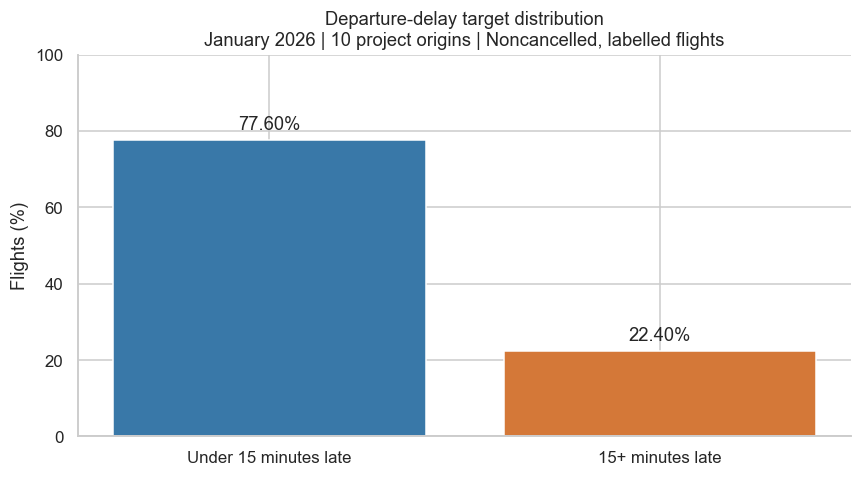

**Finding:** 22.40% of 161,992 eligible flights were delayed. Always predicting 'under 15 minutes late' gives 77.60% accuracy and zero recall for delayed flights. Later evaluation should include delayed-class precision/recall and PR-AUC alongside a baseline. No resampling or class weighting is selected from EDA alone.

In [6]:
analysis_df = df.loc[(~df["cancelled"]) & df["departure_delayed_15"].notna()].copy()
overall_rate = float(analysis_df["departure_delayed_15"].mean() * 100)
cohort_summary = pd.Series({
    "scoped_scheduled_flights": len(df),
    "cancelled_flights_excluded": int(df["cancelled"].sum()),
    "noncancelled_missing_labels_excluded": int(((~df["cancelled"]) & missing_label).sum()),
    "analysis_flights": len(analysis_df),
    "delayed_flights": int(analysis_df["departure_delayed_15"].sum()),
    "diverted_flights_retained": int(analysis_df["diverted"].sum()),
    "delay_percent": overall_rate
}, name="value")
display(cohort_summary.to_frame().round(2))
assert set(analysis_df["origin"]) == set(PROJECT_AIRPORTS)
assert not analysis_df["cancelled"].any()
assert analysis_df["departure_delayed_15"].notna().all()

target_summary = analysis_df["departure_delayed_15"].value_counts().reindex([False, True], fill_value=0).to_frame("flights")
target_summary.index.name = "delayed_15"
target_summary["percent"] = target_summary["flights"].div(len(analysis_df)).mul(100)
display(target_summary.round(2))
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(["Under 15 minutes late", "15+ minutes late"], target_summary["percent"], color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in target_summary["percent"]], padding=4)
ax.set(ylim=(0, 100), ylabel="Flights (%)", title=f"Departure-delay target distribution\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delay_distribution.png")
display(Markdown(
    f"**Finding:** {overall_rate:.2f}% of {len(analysis_df):,} eligible flights were delayed. "
    f"Always predicting 'under 15 minutes late' gives {100-overall_rate:.2f}% accuracy and zero recall for delayed flights. "
    "Later evaluation should include delayed-class precision/recall and PR-AUC alongside a baseline. "
    "No resampling or class weighting is selected from EDA alone."
))

## 4. Scheduled departure hour

Exploratory schedule columns are derived locally in the notebook. Reusable implementations will later live in
`src/features/flight_features.py`; the empty feature scripts are not changed by this EDA.
HHMM `2400` maps to hour 0 only. Full timestamps require an explicit next-day rule and airport timezones.
The rates below use each origin's local hour, not a common UTC hour. Empty hours have an undefined rate, not a zero rate.

,flights,delayed_flights,delayed_percent
scheduled_departure_hour,,,
0,456,83,18.20
1,23,8,34.78
2,0,0,NaN
3,0,0,NaN
4,0,0,NaN
5,1571,139,8.85
6,4631,431,9.31
7,9519,1145,12.03
8,13114,1916,14.61


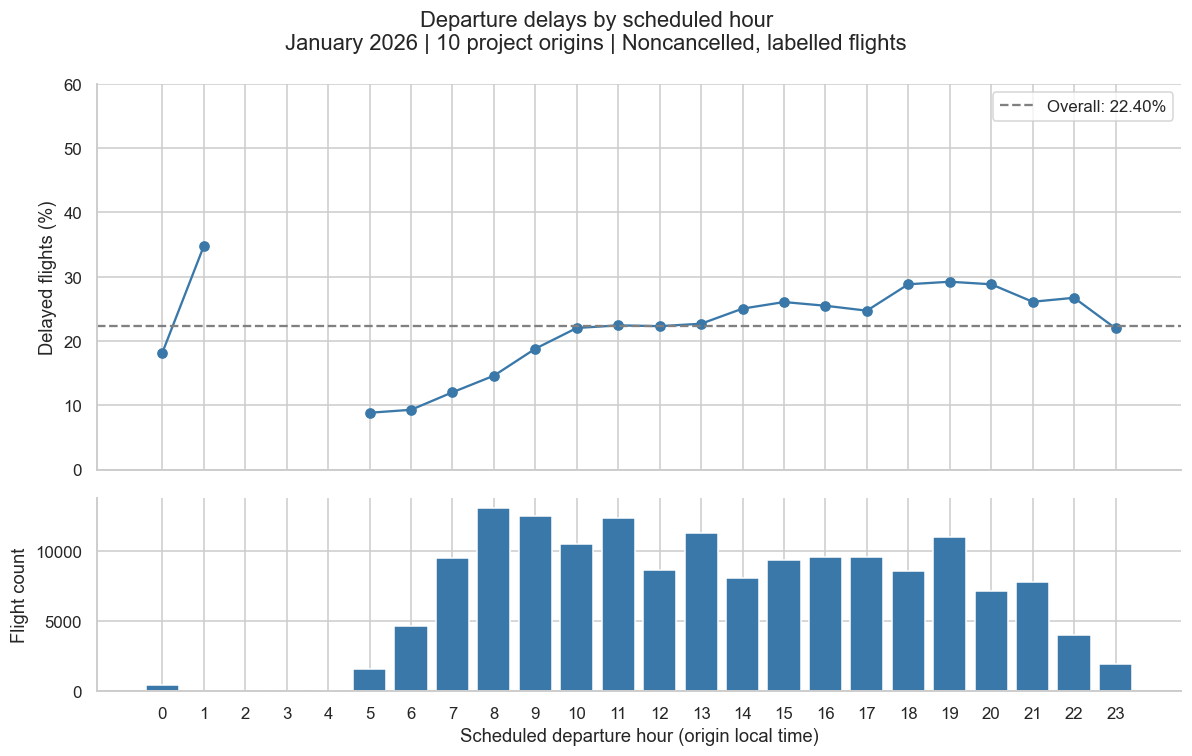

**Finding:** at 06:00, 9.31% were delayed (n=4,631); at 19:00, 29.22% (n=11,040). Empty hour buckets: [2, 3, 4]. Sparse overnight buckets have weaker support. This is an aggregate association, not evidence that departure hour causes delays.

In [7]:
analysis_df["scheduled_departure_hour"] = analysis_df["scheduled_departure_hhmm"].astype("string").str[:2].astype("Int64").mod(24)
analysis_df["is_weekend"] = analysis_df["day_of_week"].isin([6, 7])
analysis_df["invalid_scheduled_duration"] = analysis_df["scheduled_elapsed_minutes"].le(0)
analysis_df["scheduled_duration_for_eda"] = analysis_df["scheduled_elapsed_minutes"].where(analysis_df["scheduled_elapsed_minutes"].gt(0))
hourly_summary = delay_summary(analysis_df, "scheduled_departure_hour").reindex(range(24))
for column in ["flights", "delayed_flights"]:
    hourly_summary[column] = hourly_summary[column].fillna(0).astype(int)
display(hourly_summary[["flights", "delayed_flights", "delayed_percent"]].round(2))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(hourly_summary.index, hourly_summary["delayed_percent"], marker="o", color=BLUE)
axes[0].axhline(overall_rate, color="gray", ls="--", label=f"Overall: {overall_rate:.2f}%")
axes[0].set(ylabel="Delayed flights (%)", ylim=(0, 60))
axes[0].legend()
axes[1].bar(hourly_summary.index, hourly_summary["flights"], color=BLUE)
axes[1].set(xlabel="Scheduled departure hour (origin local time)", ylabel="Flight count", xticks=range(24))
fig.suptitle(f"Departure delays by scheduled hour\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_by_hour.png")
empty_hours = hourly_summary.index[hourly_summary["flights"].eq(0)].tolist()
display(Markdown(
    f"**Finding:** at 06:00, {hourly_summary.loc[6, 'delayed_percent']:.2f}% were delayed "
    f"(n={hourly_summary.loc[6, 'flights']:,}); at 19:00, {hourly_summary.loc[19, 'delayed_percent']:.2f}% "
    f"(n={hourly_summary.loc[19, 'flights']:,}). Empty hour buckets: {empty_hours}. "
    "Sparse overnight buckets have weaker support. This is an aggregate association, not evidence that departure hour causes delays."
))

## 5. Operating airlines

Rates reflect each carrier's observed mix of flights departing from the project airports, not nationwide performance.
The operating carrier may differ from the airline selling a ticket. The flight-count panel must be read with the rate panel.

,airline_name,flights,delayed_flights,delayed_percent
carrier,,,,
G4,Allegiant Air,32,11,34.38
NK,Spirit Airlines,1476,494,33.47
AA,American Airlines,25346,7304,28.82
F9,Frontier Airlines,5573,1529,27.44
B6,JetBlue Airways,3780,953,25.21
AS,Alaska Airlines,8586,2013,23.45
OO,SkyWest Airlines,25809,5854,22.68
YX,Republic Airways,4401,902,20.50
WN,Southwest Airlines,16698,3407,20.40


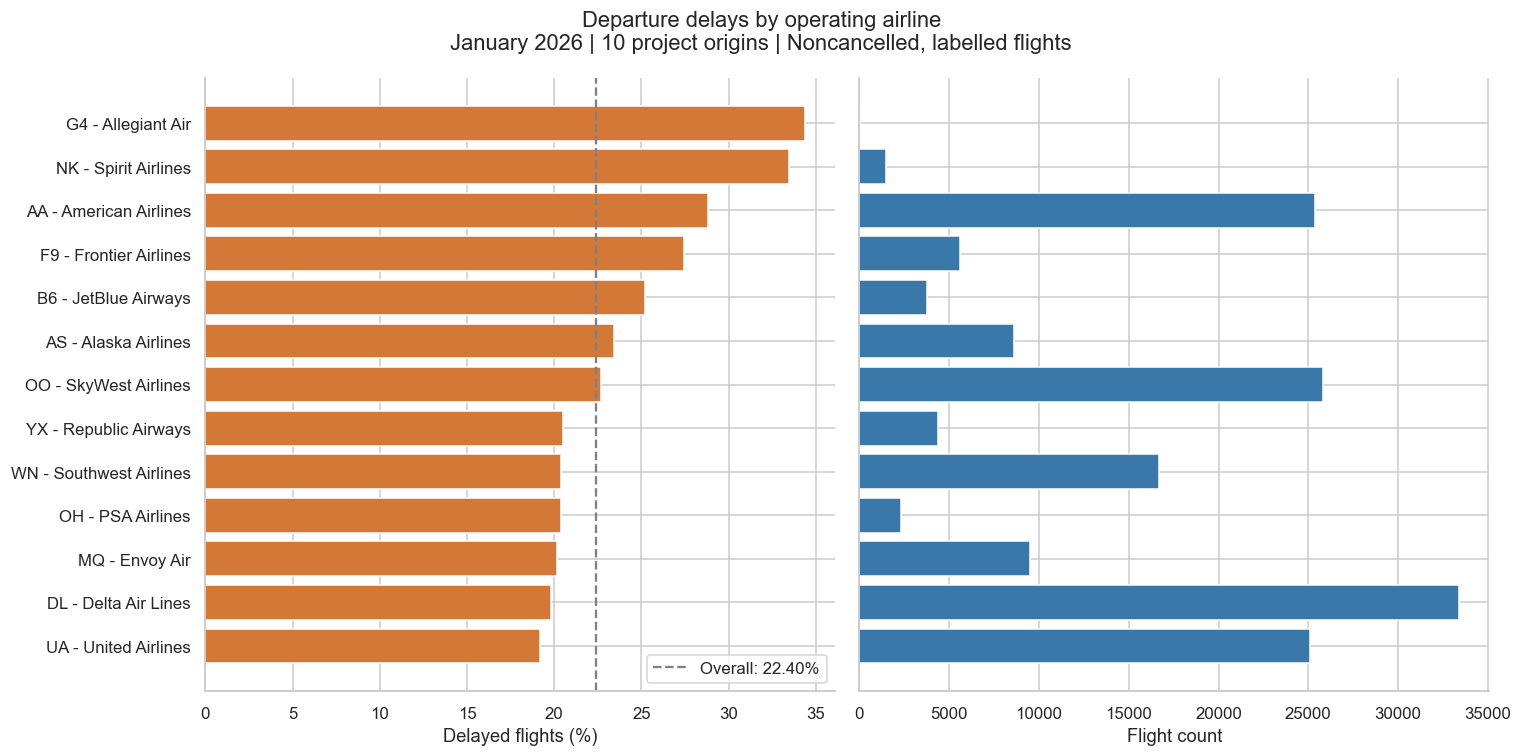

**Finding:** the smallest carrier group has only 32 flights. Do not interpret its rate as a stable carrier ranking. Carrier is a candidate categorical feature; route, airport, timing, weather, and exclusion of cancellations can explain part of the observed differences.

In [8]:
AIRLINE_NAMES = {
    "AA": "American Airlines", "AS": "Alaska Airlines", "B6": "JetBlue Airways",
    "DL": "Delta Air Lines", "F9": "Frontier Airlines", "G4": "Allegiant Air",
    "MQ": "Envoy Air", "NK": "Spirit Airlines", "OH": "PSA Airlines",
    "OO": "SkyWest Airlines", "UA": "United Airlines", "WN": "Southwest Airlines",
    "YX": "Republic Airways"
}
airline_summary = delay_summary(analysis_df, "carrier").sort_values("delayed_percent", ascending=False)
airline_summary["airline_name"] = airline_summary.index.map(AIRLINE_NAMES)
display(airline_summary[["airline_name", "flights", "delayed_flights", "delayed_percent"]].round(2))

airline_plot = airline_summary.sort_values("delayed_percent")
y = np.arange(len(airline_plot))
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
axes[0].barh(y, airline_plot["delayed_percent"], color=ORANGE)
axes[0].axvline(overall_rate, color="gray", ls="--", label=f"Overall: {overall_rate:.2f}%")
axes[0].set_yticks(y, [f"{k} - {AIRLINE_NAMES.get(k, k)}" for k in airline_plot.index])
axes[0].set_xlabel("Delayed flights (%)")
axes[0].legend(loc="lower right")
axes[1].barh(y, airline_plot["flights"], color=BLUE)
axes[1].set_xlabel("Flight count")
axes[1].tick_params(axis="y", labelleft=False)
fig.suptitle(f"Departure delays by operating airline\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_by_airline.png")
smallest_carrier = airline_summary.loc[airline_summary["flights"].idxmin()]
display(Markdown(
    f"**Finding:** the smallest carrier group has only {int(smallest_carrier['flights']):,} flights. "
    "Do not interpret its rate as a stable carrier ranking. Carrier is a candidate categorical feature; "
    "route, airport, timing, weather, and exclusion of cancellations can explain part of the observed differences."
))

## 6. Origin airports

All ten project origins are shown. Destinations remain unrestricted. Counts and rates use eligible departures,
so these are not airport-wide traffic statistics including arrivals or cancelled departures.

,airport_name,flights,delayed_flights,delayed_percent
origin,,,,
ORD,Chicago O'Hare International,24192,7138,29.51
DEN,Denver International,24070,4509,18.73
ATL,Hartsfield-Jackson Atlanta International,23365,4934,21.12
DFW,Dallas Fort Worth International,21842,5814,26.62
PHX,Phoenix Sky Harbor International,16176,3183,19.68
LAX,Los Angeles International,14493,2800,19.32
SEA,Seattle-Tacoma International,11699,2332,19.93
SFO,San Francisco International,10843,2000,18.45
MSP,Minneapolis-Saint Paul International,7861,1847,23.50


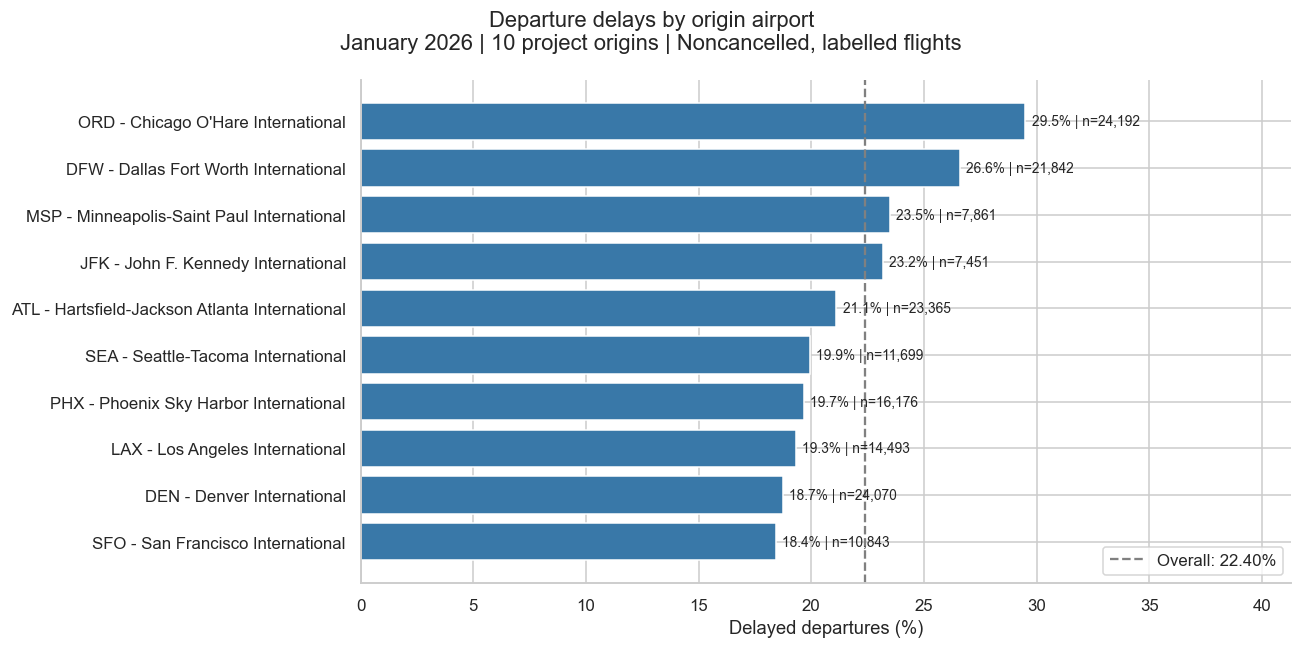

**Finding:** ORD has the highest observed rate (29.51%) and SFO the lowest (18.45%). Origin is a candidate categorical feature. These differences do not establish airport causation or predict performance in other months.

In [9]:
AIRPORT_NAMES = {
    "ATL": "Hartsfield-Jackson Atlanta International", "DEN": "Denver International",
    "DFW": "Dallas Fort Worth International", "JFK": "John F. Kennedy International",
    "LAX": "Los Angeles International", "MSP": "Minneapolis-Saint Paul International",
    "ORD": "Chicago O'Hare International", "PHX": "Phoenix Sky Harbor International",
    "SEA": "Seattle-Tacoma International", "SFO": "San Francisco International"
}
airport_summary = delay_summary(analysis_df, "origin")
airport_summary["airport_name"] = airport_summary.index.map(AIRPORT_NAMES)
display(airport_summary[["airport_name", "flights", "delayed_flights", "delayed_percent"]].sort_values("flights", ascending=False).round(2))

airport_plot = airport_summary.sort_values("delayed_percent")
fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(airport_plot))
bars = ax.barh(y, airport_plot["delayed_percent"], color=BLUE)
ax.set_yticks(y, [f"{k} - {AIRPORT_NAMES[k]}" for k in airport_plot.index])
ax.bar_label(bars, labels=[f"{r.delayed_percent:.1f}% | n={r.flights:,}" for r in airport_plot.itertuples()], padding=4, fontsize=9)
ax.axvline(overall_rate, color="gray", ls="--", label=f"Overall: {overall_rate:.2f}%")
ax.set(xlabel="Delayed departures (%)", xlim=(0, float(airport_plot['delayed_percent'].max())*1.4))
ax.legend(loc="lower right")
fig.suptitle(f"Departure delays by origin airport\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_by_airport.png")
high_airport, low_airport = airport_summary["delayed_percent"].idxmax(), airport_summary["delayed_percent"].idxmin()
display(Markdown(
    f"**Finding:** {high_airport} has the highest observed rate ({airport_summary.loc[high_airport, 'delayed_percent']:.2f}%) "
    f"and {low_airport} the lowest ({airport_summary.loc[low_airport, 'delayed_percent']:.2f}%). "
    "Origin is a candidate categorical feature. These differences do not establish airport causation or predict performance in other months."
))

## 7. Weekday, weekend, and individual dates

A month contains only four or five occurrences of each weekday. A storm or other event on a few dates can
look like a weekday effect. Compare the weekday averages with the daily time series before drawing conclusions.
Cancellation rates use **all scoped scheduled flights**; delay rates use the eligible modelling population.

,weekday,flights,delayed_flights,delayed_percent
day_of_week,,,,
1,Monday,21609,5953,27.55
2,Tuesday,19797,3513,17.75
3,Wednesday,20261,3411,16.84
4,Thursday,28085,5700,20.30
5,Friday,28317,6602,23.31
6,Saturday,23376,5581,23.87
7,Sunday,20547,5523,26.88


,flights,delayed_flights,delayed_percent
is_weekend,,,
Weekday,118069,25179,21.33
Weekend,43923,11104,25.28


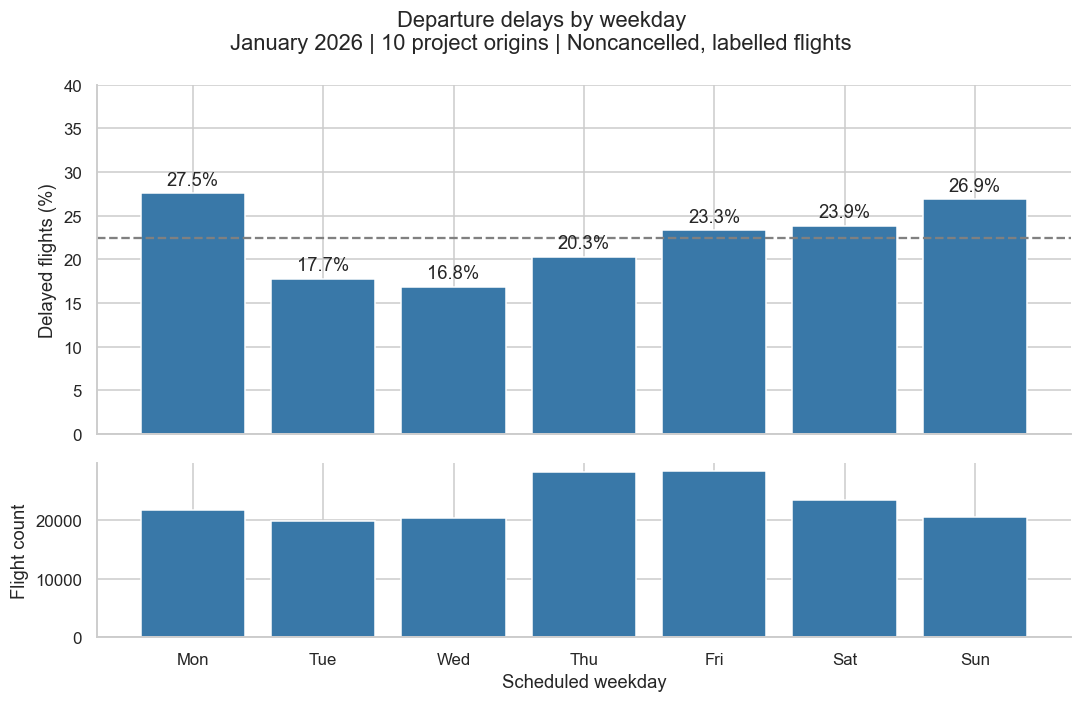

In [10]:
WEEKDAYS = {1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday", 5: "Friday", 6: "Saturday", 7: "Sunday"}
weekday_summary = delay_summary(analysis_df, "day_of_week").reindex(range(1, 8))
weekday_summary["weekday"] = weekday_summary.index.map(WEEKDAYS)
display(weekday_summary[["weekday", "flights", "delayed_flights", "delayed_percent"]].round(2))
weekend_summary = delay_summary(analysis_df, "is_weekend")
weekend_summary.index = weekend_summary.index.map({False: "Weekday", True: "Weekend"})
display(weekend_summary[["flights", "delayed_flights", "delayed_percent"]].round(2))
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(7)
bars = axes[0].bar(x, weekday_summary["delayed_percent"], color=BLUE)
axes[0].bar_label(bars, labels=[f"{v:.1f}%" for v in weekday_summary["delayed_percent"]], padding=3)
axes[0].axhline(overall_rate, color="gray", ls="--")
axes[0].set(ylabel="Delayed flights (%)", ylim=(0, max(40, float(weekday_summary['delayed_percent'].max())*1.2)))
axes[1].bar(x, weekday_summary["flights"], color=BLUE)
axes[1].set(xticks=x, xticklabels=[WEEKDAYS[i][:3] for i in range(1, 8)], ylabel="Flight count", xlabel="Scheduled weekday")
fig.suptitle(f"Departure delays by weekday\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_by_weekday.png")

,flights,delayed_percent,scheduled_flights,cancellations,cancelled_percent
flight_date,,,,,
2026-01-01,5504,28.74,5534,30,0.54
2026-01-02,6158,27.93,6211,53,0.85
2026-01-03,5714,33.27,5895,181,3.07
2026-01-04,6120,34.33,6219,99,1.59
2026-01-05,5908,31.30,5973,65,1.09
2026-01-06,5164,16.01,5176,12,0.23
2026-01-07,5129,11.44,5136,7,0.14
2026-01-08,5567,20.08,5579,12,0.22
2026-01-09,5574,16.09,5579,5,0.09


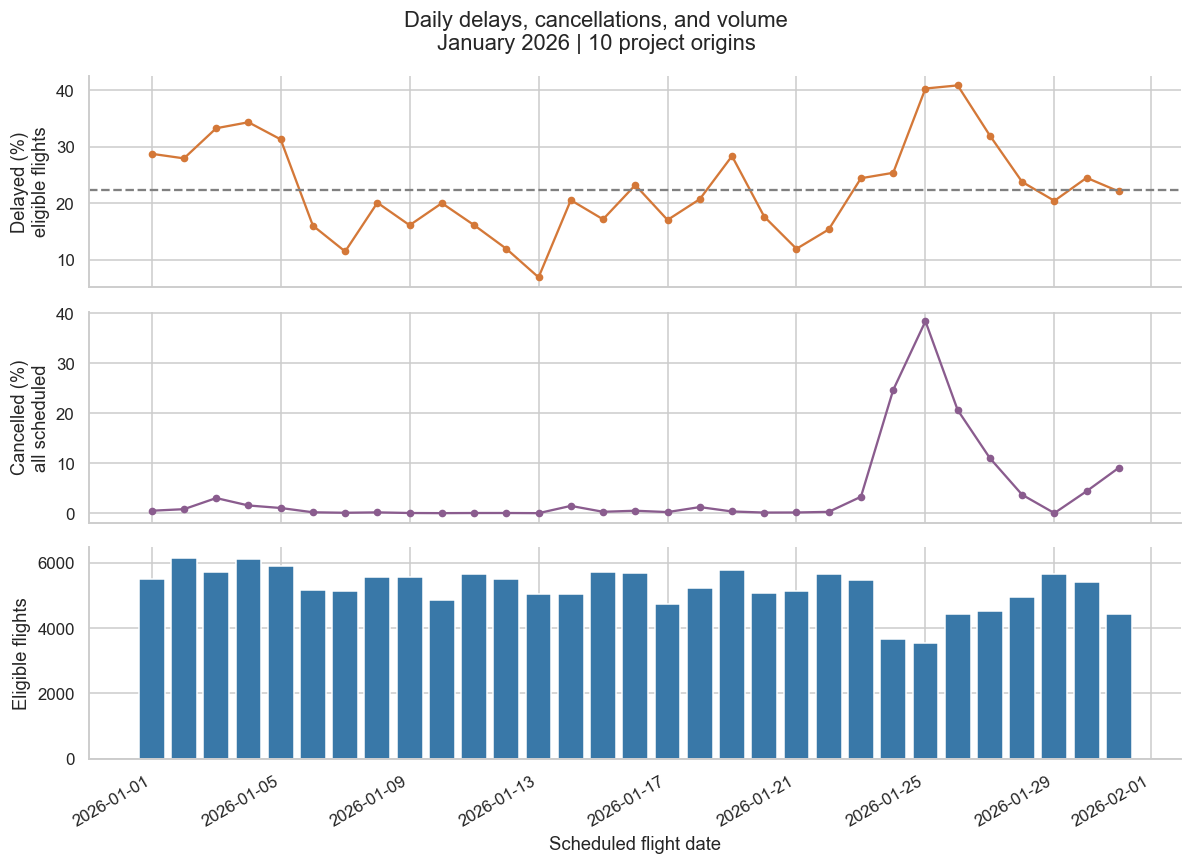

**Finding:** the largest daily eligible-flight delay rate occurs on 2026-01-26: 40.86% (n=4,435). This notebook does not identify the cause. Cancellation exclusions can change which flights remain on disrupted dates. Do not attribute peaks to weather without matching historical observations.

In [11]:
daily_summary = delay_summary(analysis_df, "flight_date")
daily_scheduled = df.groupby("flight_date").agg(
    scheduled_flights=("flight_id", "size"), cancellations=("cancelled", "sum")
)
daily_scheduled["cancelled_percent"] = 100 * daily_scheduled["cancellations"] / daily_scheduled["scheduled_flights"]
daily_summary = daily_summary.join(daily_scheduled)
display(daily_summary[["flights", "delayed_percent", "scheduled_flights", "cancellations", "cancelled_percent"]].round(2))
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(daily_summary.index, daily_summary["delayed_percent"], marker="o", ms=4, color=ORANGE)
axes[0].axhline(overall_rate, color="gray", ls="--")
axes[0].set_ylabel("Delayed (%)\neligible flights")
axes[1].plot(daily_summary.index, daily_summary["cancelled_percent"], marker="o", ms=4, color="#8A5C8E")
axes[1].set_ylabel("Cancelled (%)\nall scheduled")
axes[2].bar(daily_summary.index, daily_summary["flights"], color=BLUE)
axes[2].set(ylabel="Eligible flights", xlabel="Scheduled flight date")
fig.suptitle("Daily delays, cancellations, and volume\nJanuary 2026 | 10 project origins")
fig.autofmt_xdate(rotation=30)
finish_figure(fig, "departure_delays_by_date.png")
peak_day = daily_summary["delayed_percent"].idxmax()
display(Markdown(
    f"**Finding:** the largest daily eligible-flight delay rate occurs on {peak_day:%Y-%m-%d}: "
    f"{daily_summary.loc[peak_day, 'delayed_percent']:.2f}% (n={int(daily_summary.loc[peak_day, 'flights']):,}). "
    "This notebook does not identify the cause. Cancellation exclusions can change which flights remain on disrupted dates. "
    "Do not attribute peaks to weather without matching historical observations."
))

**Weekday interpretation:** Monday and Sunday have higher observed delay rates than Tuesday and Wednesday in this month. These are candidates for calendar features, not evidence of a recurring weekly effect; the daily plot reveals substantial date-level variation.

## 8. Departure-delay magnitude and outliers

The binary target hides how severe delays are. Negative departure delay means an early departure, not a bad value.
The histogram shows only -30 through 180 minutes for readability. Records outside that window remain in the data;
full-data quantiles and extrema are reported separately. No outliers are deleted or capped for training here.

,delay_minutes
count,161992.00000
mean,14.15118
std,56.50312
min,-40.00000
50%,-2.00000
90%,48.00000
95%,88.00000
99%,224.00000
max,2270.00000


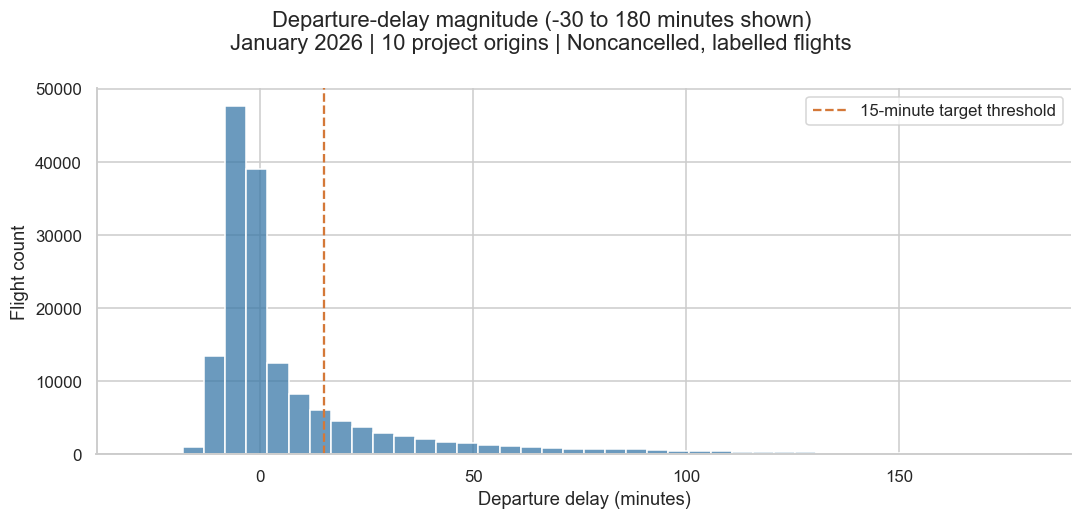

**Display coverage:** 159,428 of 161,992 measured delays (98.42%). 2,564 records outside the display window are retained. Actual delay is an outcome and must not become a predeparture input feature.

In [12]:
delay_values = analysis_df["departure_delay_minutes"].dropna()
display(delay_values.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("delay_minutes"))
window = delay_values.between(-30, 180)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(x=delay_values.loc[window], binwidth=5, color=BLUE, ax=ax)
ax.axvline(15, color=ORANGE, ls="--", label="15-minute target threshold")
ax.set(xlabel="Departure delay (minutes)", ylabel="Flight count")
ax.legend()
fig.suptitle(f"Departure-delay magnitude (-30 to 180 minutes shown)\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delay_magnitude.png")
display(Markdown(
    f"**Display coverage:** {int(window.sum()):,} of {len(delay_values):,} measured delays "
    f"({window.mean()*100:.2f}%). {int((~window).sum()):,} records outside the display window are retained. "
    "Actual delay is an outcome and must not become a predeparture input feature."
))

## 9. Distance and planned duration

Distance and planned duration are candidate predeparture inputs. Invalid duration is represented as missing in
`scheduled_duration_for_eda`, while the stored source measurement remains unchanged. Missing-value treatment for a model
will be selected later and fitted on training data only.
Distance bins are descriptive, predefined ranges; their rates are not target encodings for training.

,distance_miles,scheduled_elapsed_minutes,scheduled_duration_for_eda
count,161992.00,161992.00,161991.00
mean,932.97,159.00,159.00
std,656.99,78.84,78.84
min,67.00,-64.00,44.00
50%,761.00,140.00,140.00
90%,1927.00,276.00,276.00
99%,2677.00,390.00,390.00
max,4983.00,683.00,683.00


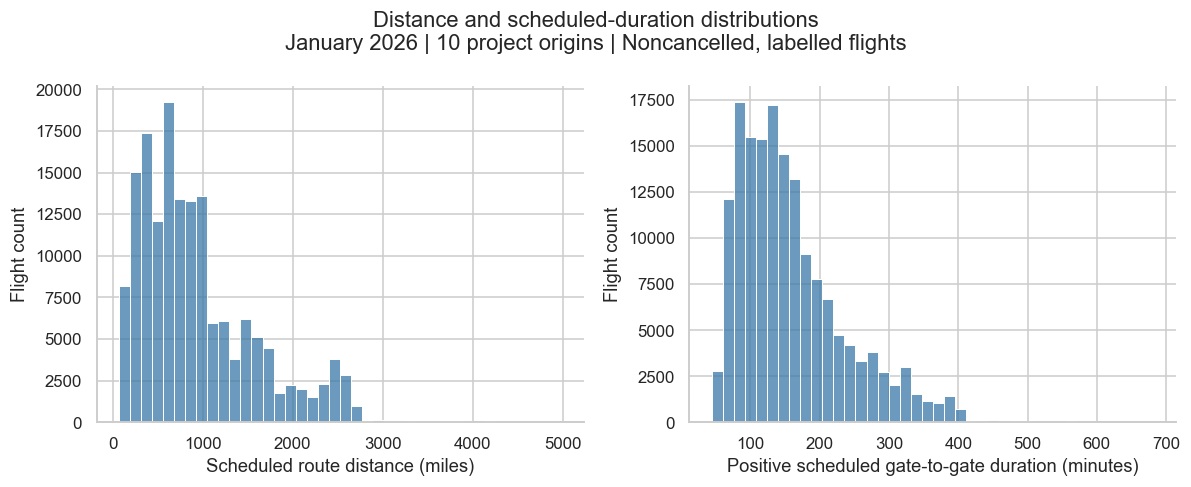

,flights,delayed_flights,delayed_percent
distance_band,,,
0 to <500,46210,10129,21.92
"500 to <1,000",60132,13360,22.22
"1,000 to <1,500",26047,6145,23.59
"1,500 to <2,000",15344,3562,23.21
"2,000+",14259,3087,21.65


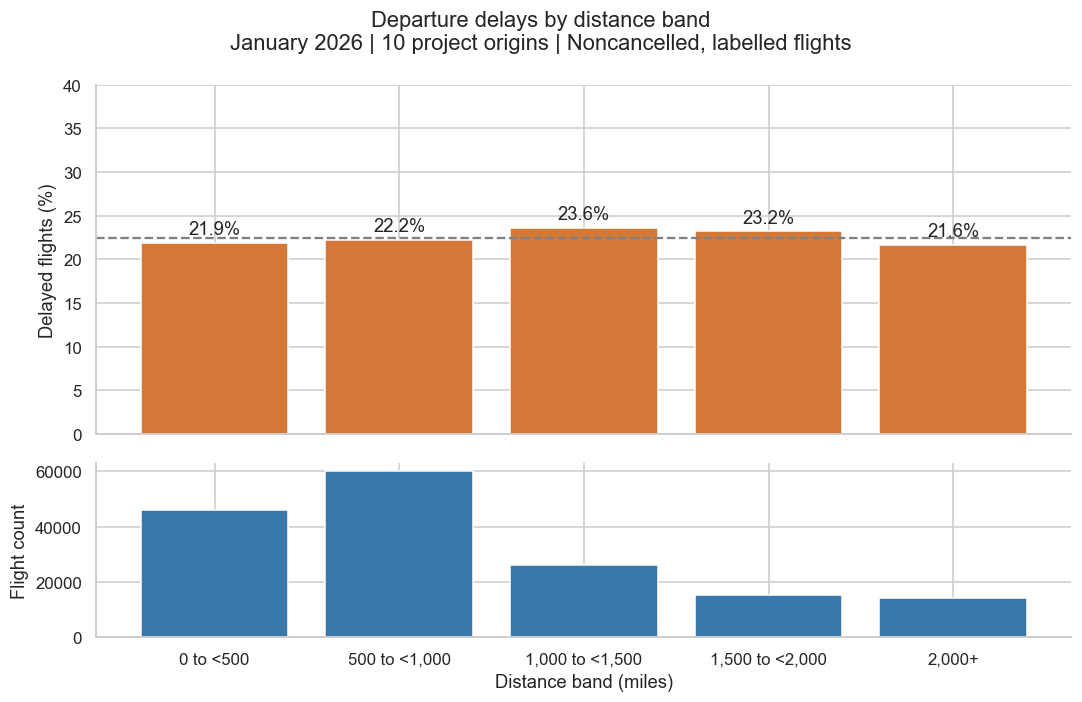

In [13]:
display(analysis_df[["distance_miles", "scheduled_elapsed_minutes", "scheduled_duration_for_eda"]].describe(percentiles=[.5, .9, .99]).round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(data=analysis_df, x="distance_miles", bins=40, color=BLUE, ax=axes[0])
sns.histplot(data=analysis_df, x="scheduled_duration_for_eda", bins=40, color=BLUE, ax=axes[1])
axes[0].set(xlabel="Scheduled route distance (miles)", ylabel="Flight count")
axes[1].set(xlabel="Positive scheduled gate-to-gate duration (minutes)", ylabel="Flight count")
fig.suptitle(f"Distance and scheduled-duration distributions\n{SCOPE_LABEL}")
finish_figure(fig, "flight_distance_and_duration.png")

analysis_df["distance_band"] = pd.cut(
    analysis_df["distance_miles"], bins=[0, 500, 1000, 1500, 2000, np.inf], right=False,
    labels=["0 to <500", "500 to <1,000", "1,000 to <1,500", "1,500 to <2,000", "2,000+"]
)
distance_summary = delay_summary(analysis_df, "distance_band")
display(distance_summary[["flights", "delayed_flights", "delayed_percent"]].round(2))
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(len(distance_summary))
bars = axes[0].bar(x, distance_summary["delayed_percent"], color=ORANGE)
axes[0].bar_label(bars, labels=[f"{v:.1f}%" for v in distance_summary["delayed_percent"]], padding=3)
axes[0].axhline(overall_rate, color="gray", ls="--")
axes[0].set(ylabel="Delayed flights (%)", ylim=(0, max(40, float(distance_summary['delayed_percent'].max())*1.2)))
axes[1].bar(x, distance_summary["flights"], color=BLUE)
axes[1].set(xticks=x, xticklabels=distance_summary.index.astype(str), xlabel="Distance band (miles)", ylabel="Flight count")
fig.suptitle(f"Departure delays by distance band\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_by_distance.png")

**Numeric-feature interpretation:** delay rates differ modestly across the displayed distance bands, with no simple monotonic increase. Distance is known before departure and remains a candidate; these summaries do not prove incremental model value. Planned duration is gate-to-gate time, not measured airborne time.

## 10. Airport-by-hour comparison

A Seaborn heatmap is appropriate for this rectangular comparison (not a geographic map).
Each cell is a delay percentage for an origin/hour combination. Cells with fewer than **100 eligible flights** are masked
as a presentation rule to reduce emphasis on very sparse groups. The threshold is not a training exclusion or a statistical guarantee.
A blank cell means insufficient support or no flights, not zero delay.

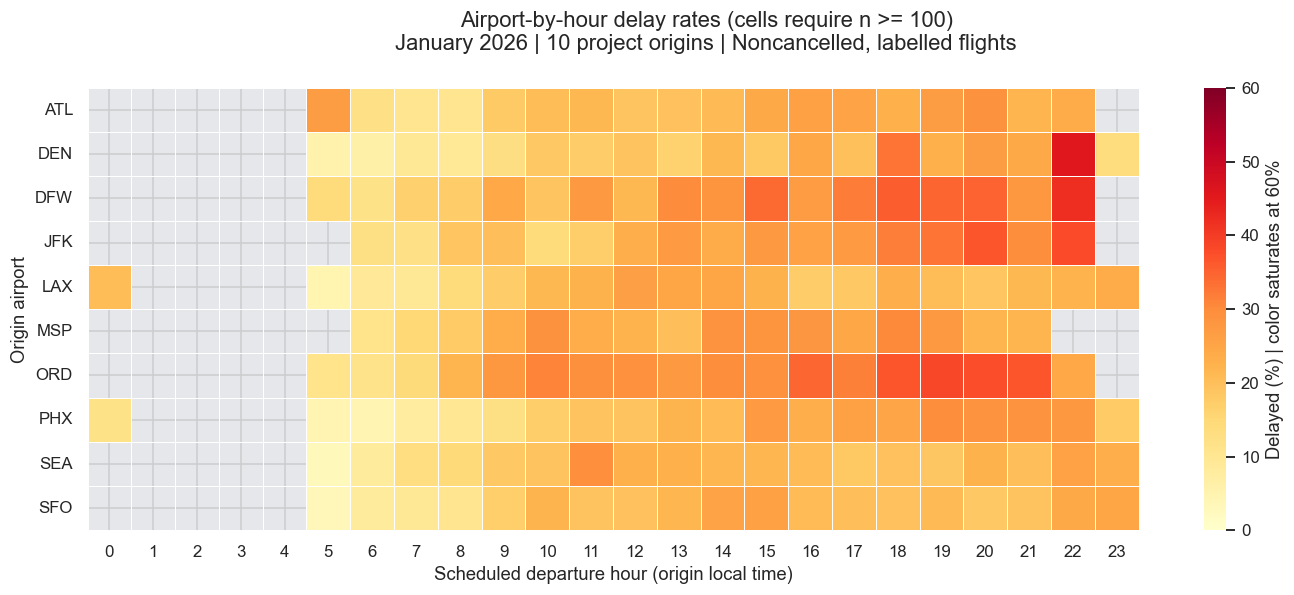

In [14]:
airport_hour = delay_summary(analysis_df, ["origin", "scheduled_departure_hour"])
heat_rates = airport_hour["delayed_percent"].unstack().reindex(index=PROJECT_AIRPORTS, columns=range(24))
heat_counts = airport_hour["flights"].unstack().reindex(index=PROJECT_AIRPORTS, columns=range(24)).fillna(0)
MIN_HEATMAP_FLIGHTS = 100
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.set_facecolor("#E5E7EB")
sns.heatmap(
    heat_rates.astype(float), mask=heat_counts.lt(MIN_HEATMAP_FLIGHTS), cmap="YlOrRd", vmin=0, vmax=60,
    linewidths=.4, linecolor="white", cbar_kws={"label": "Delayed (%) | color saturates at 60%"}, ax=ax
)
ax.set(xlabel="Scheduled departure hour (origin local time)", ylabel="Origin airport")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.suptitle(f"Airport-by-hour delay rates (cells require n >= 100)\n{SCOPE_LABEL}")
finish_figure(fig, "departure_delays_airport_hour.png")

## 11. Findings and feature decisions

These are exploratory candidates, not claims of predictive improvement. Aggregated delay rates above must not be
joined back onto all flights as model inputs: that would use target information. Any learned encoding must be fitted
inside the training split. No encoders, scalers, imputers, feature selection, or models are fitted in this notebook.

In [15]:
feature_decisions = pd.DataFrame([
    ("scheduled_departure_hour", "Candidate", "Observed hourly variation; preserve 2400 handling. Explore cyclic encoding during modelling."),
    ("day_of_week / is_weekend", "Candidate", "Calendar context; only a few examples of each weekday in January, so stability is unproven."),
    ("carrier", "Candidate", "Observed group variation; sparse carrier groups require care. Encode using training data only."),
    ("origin / destination", "Candidate", "Known route context; restrict origins to the ten-airport project scope."),
    ("distance_miles", "Candidate", "Available before departure; validate positive values and retain continuous values initially."),
    ("scheduled duration + invalid flag", "Candidate", "Replace nonpositive values with missing in features; retain source values for traceability."),
    ("flight_month", "Defer", "Constant at January in this dataset, so it cannot distinguish these records."),
    ("flight_date", "Split / audit", "Use chronological train/validation/test boundaries; do not treat an identifier as evidence of generalization."),
    ("historical weather", "Pending", "Need observations matching January 2026, airport identifiers, UTC conversion, and prediction cutoff."),
    ("departure_delayed_15", "Target only", "The outcome being predicted, never an input."),
    ("actual delay, cancellation, diversion", "Exclude as predeparture inputs", "Post-event information. Cancellation defines the analysis cohort; diversion is retained only for audit."),
    ("flight_id / outcome_flight_id", "Exclude", "Database identifiers without intended predictive meaning.")
], columns=["field", "decision", "reason"])
with pd.option_context("display.max_colwidth", 120):
    display(feature_decisions)

assert len(analysis_df) == int(target_summary["flights"].sum())
assert len(analysis_df) == int(airline_summary["flights"].sum()) == int(airport_summary["flights"].sum())
assert len(analysis_df) == int(hourly_summary["flights"].sum())
assert airport_summary["delayed_percent"].between(0, 100).all()
assert hourly_summary.loc[hourly_summary["flights"].eq(0), "delayed_percent"].isna().all()
display(Markdown(
    f"### Results for this database snapshot\n"
    f"- **{len(analysis_df):,} eligible flights; {int(analysis_df['departure_delayed_15'].sum()):,} delayed ({overall_rate:.2f}%).**\n"
    f"- Origin rates range from **{airport_summary['delayed_percent'].min():.2f}% to {airport_summary['delayed_percent'].max():.2f}%**.\n"
    f"- **{int(invalid_duration.sum()):,} source-duration anomaly record(s)** occur among all scoped scheduled flights; "
    f"**{int(analysis_df['invalid_scheduled_duration'].sum()):,}** remain(s) in the eligible cohort.\n"
    "- Hourly, airline, airport, weekday, daily, and distance comparisons are descriptive and unadjusted.\n"
    f"- **{len(exported_figures)} PNG charts** saved for GitHub; no interactive maps or credentials are embedded."
))
print("All notebook consistency checks passed.")

,field,decision,reason
0,scheduled_departure_hour,Candidate,Observed hourly variation; preserve 2400 handling. Explore cyclic encoding during modelling.
1,day_of_week / is_weekend,Candidate,"Calendar context; only a few examples of each weekday in January, so stability is unproven."
2,carrier,Candidate,Observed group variation; sparse carrier groups require care. Encode using training data only.
3,origin / destination,Candidate,Known route context; restrict origins to the ten-airport project scope.
4,distance_miles,Candidate,Available before departure; validate positive values and retain continuous values initially.
5,scheduled duration + invalid flag,Candidate,Replace nonpositive values with missing in features; retain source values for traceability.
6,flight_month,Defer,"Constant at January in this dataset, so it cannot distinguish these records."
7,flight_date,Split / audit,Use chronological train/validation/test boundaries; do not treat an identifier as evidence of generalization.
8,historical weather,Pending,"Need observations matching January 2026, airport identifiers, UTC conversion, and prediction cutoff."
9,departure_delayed_15,Target only,"The outcome being predicted, never an input."


### Results for this database snapshot
- **161,992 eligible flights; 36,283 delayed (22.40%).**
- Origin rates range from **18.45% to 29.51%**.
- **1 source-duration anomaly** occurs among all scoped scheduled flights; **1** remains in the eligible cohort.
- Hourly, airline, airport, weekday, daily, and distance comparisons are descriptive and unadjusted.
- **10 PNG charts** saved for GitHub; no interactive maps or credentials are embedded.

All notebook consistency checks passed.


### Limits and next step

- **One month only:** findings describe January 2026 at ten origins, not all airports or seasons.
- **Selection:** cancelled flights are excluded from the delay model, and cancellation patterns can change observed rates.
- **Dependence:** flights share dates, airports, aircraft operations, and disruptions; group rates are not controlled causal effects.
- **Prediction time:** define a fixed predeparture cutoff before joining weather. Historical observations must be available by that cutoff;
  current weather cannot describe January flights. HHMM, timezone conversion, and 2400 date rollover need explicit rules.
- **Evaluation:** reserve later dates for validation/test. Do not randomly split rows and claim future-date performance.
  All target-aware processing and fitted transformations belong inside training only. No prediction-performance claim has been made.
- **Next implementation:** put reviewed flight transformations in `src/features/flight_features.py`; keep future weather transformations in
  `src/features/weather_features.py`. Then obtain matching historical weather for the same ten origins. This notebook does not modify either script.

### GitHub presentation

Save this notebook with its outputs. PNGs are under `reports/figures/`. Reference them from the README with relative Markdown links,
for example `![Delays by airport](reports/figures/departure_delays_by_airport.png)`.
The raw CSV and `.env` stay untracked. Re-running requires the database and listed Python dependencies; saved outputs remain viewable without them.